# Prompt Engineering для анализа сентимента

**Задача:** классификация тональности русскоязычных текстов (3 класса: положительный / нейтральный / отрицательный)
инструктивной LLM **Qwen/Qwen2.5-1.5B-Instruct** без дообучения — только за счёт формулировок prompt,
system prompt и параметров генерации.

**План ноутбука** (по пунктам задания):

| Раздел | Пункт задания | Что делаем |
|---|---|---|
| 1. Данные | п.1 | `sy-volkov/russian-sentiment-analysis-dataset`, EDA, формирование оценочной подвыборки |
| 2. Базовый prompt | п.2 | первый prompt без system prompt, greedy-декодинг, функция постобработки ответа |
| 3. Вариации prompt | п.3 | строгость ограничений, форматы ввода/вывода, RU/EN, структура инструкции |
| 4. System prompt | п.4 | сетка «лучшие промпты × system prompts» |
| 5. Стратегии генерации | п.5 | greedy / beam search / сэмплирование (temperature, top-k, top-p) / self-consistency |

Железо: Apple M1 Max (64 ГБ), устройство `mps`, модель в bfloat16. Все метрики логируются в `logs/metrics.jsonl`.

## 0. Настройка окружения

Загружаем модель и токенизатор. Важный нюанс: в `generation_config` Qwen2.5 «зашиты» параметры сэмплирования
(`do_sample=True, temperature=0.7, top_k=20, top_p=0.8, repetition_penalty=1.1`) — то есть вызов
`model.generate()` без явных аргументов **уже сэмплирует**, а не генерирует жадно. Для чистоты экспериментов
зачищаем дефолты конфига и в каждом вызове передаём все параметры генерации явно.

In [1]:
import json
import re
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

SEED = 42
set_seed(SEED)

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"

tok = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.bfloat16).to(DEVICE).eval()

print(f"устройство: {DEVICE}, параметров: {model.num_parameters():,}")
print(f"дефолтный generation_config: {model.generation_config}")

# зачищаем sampling-дефолты Qwen, чтобы greedy был честным и без предупреждений
for p in ("temperature", "top_p", "top_k", "repetition_penalty"):
    setattr(model.generation_config, p, None)
model.generation_config.do_sample = False

# палитра и стиль графиков
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"   # чернила и сетка
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"        # категориальные слоты 1-3
C_DARK = "#104281"                                   # акцент «лучший результат» (тёмный шаг синего)
CMAP_SEQ = LinearSegmentedColormap.from_list(
    "seq_blues", ["#fcfcfb", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#1c5cab", "#104281", "#0d366b"]
)
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
pd.set_option("display.width", 160)

LOG = Path("logs/metrics.jsonl")
LOG.parent.mkdir(exist_ok=True)
LOG.write_text("")  # каждая полный прогон ноутбука пишет лог заново

/Users/rurik/repos/otus/prompt/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


устройство: mps, параметров: 1,543,714,304
дефолтный generation_config: GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "repetition_penalty": 1.1,
  "temperature": 0.7,
  "top_k": 20,
  "top_p": 0.8
}



0

## 1. Данные (п.1 задания)

Датасет `sy-volkov/russian-sentiment-analysis-dataset` — комментарии на русском с разметкой тональности.
Колонки: `processed_text` (текст), `Class` (N/G/B), `label` (int: **0 = нейтральный, 1 = положительный, 2 = отрицательный** —
порядок нестандартный, нейтральный идёт первым).

In [2]:
ds = load_dataset("sy-volkov/russian-sentiment-analysis-dataset")["train"]
ds = ds.remove_columns("__index_level_0__")
print(ds)

CLASS_NAMES_RU = ["нейтральный", "положительный", "отрицательный"]  # по порядку label 0, 1, 2
df = ds.to_pandas()
df["len_chars"] = df["processed_text"].str.len()

counts = df["label"].value_counts().sort_index()
print("\nраспределение классов (весь датасет):")
print(pd.DataFrame({"класс": CLASS_NAMES_RU, "строк": counts.values,
                    "доля": (counts.values / len(df)).round(3)}).to_string(index=False))
print("\nдлина текстов, символов:")
print(df["len_chars"].describe().round(1).to_string())

Dataset({
    features: ['processed_text', 'Class', 'label'],
    num_rows: 3873
})

распределение классов (весь датасет):
        класс  строк  доля
  нейтральный   1771 0.457
положительный   1102 0.285
отрицательный   1000 0.258

длина текстов, символов:
count    3873.0
mean       62.5
std        64.4
min         2.0
25%        43.0
50%        55.0
75%        68.0
max      2555.0


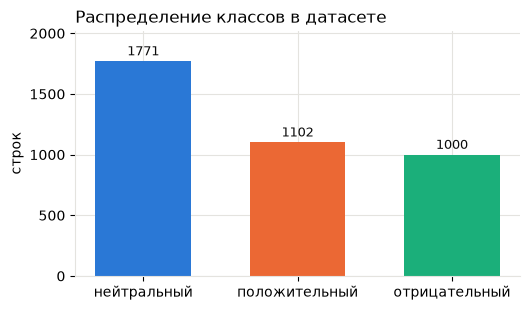

In [3]:
fig, ax = plt.subplots(figsize=(5.4, 3.2))
bars = ax.bar(CLASS_NAMES_RU, counts.values, color=[C1, C2, C3], width=0.62)
ax.bar_label(bars, fmt="%d", color=INK, fontsize=9, padding=2)
ax.set_ylabel("строк")
ax.set_title("Распределение классов в датасете", loc="left")
ax.set_ylim(0, counts.max() * 1.14)
fig.tight_layout()
plt.show()

In [4]:
for lab in (0, 1, 2):
    print(f"\n=== {CLASS_NAMES_RU[lab]} (label={lab}) ===")
    for t in df[df.label == lab]["processed_text"].head(2):
        print(" •", t)


=== нейтральный (label=0) ===
 • Картинку к новости какой-то садист рисовал
 • Интроверты, читая этот пост:  ._.

=== положительный (label=1) ===
 • Алексей, С Днем Рождения!!! Исполнения всего задуманного!!!
 • С Днём Рождения!

=== отрицательный (label=2) ===
 • Что существенного, кроме цветов, изменилось?И этого пока нет.Время реакции - не заметил.Вам что, делать нечего?Кроме креативности, конечно...
 • Спорные утверждения. Странные предложения.


In [5]:
# оценим на стратифицированной сбалансированной подвыборке: по 100 текстов на класс
N_PER_CLASS = 100
eval_df = df.groupby("label").sample(n=N_PER_CLASS, random_state=SEED).reset_index(drop=True)
texts = eval_df["processed_text"].tolist()
LABELS = eval_df["label"].tolist()
print(f"оценочная выборка: {len(texts)} текстов, баланс классов: {Counter(LABELS)}")
print(f"baseline «всё нейтральное» (мажоранта полного датасета): accuracy = "
      f"{accuracy_score(LABELS, [0] * len(LABELS)):.3f}")
print(f"baseline «случайное угадывание» (равномерное): accuracy = {1 / 3:.3f}")

оценочная выборка: 300 текстов, баланс классов: Counter({0: 100, 1: 100, 2: 100})
baseline «всё нейтральное» (мажоранта полного датасета): accuracy = 0.333
baseline «случайное угадывание» (равномерное): accuracy = 0.333


**Почему так сформирована оценка.** Генерация 300 текстов × ~30 конфигураций экспериментов на `mps` —
это уже десятки тысяч генераций; полные 3873 текста делали бы ноутбук многочасовым без выигрыша для выводов.
Подвыборка сбалансирована (по 100 на класс), поэтому accuracy и macro-F1 ведут себя согласованно,
а confusion matrix читается без поправок на дисбаланс. Нераспознанные ответы модели приписываются
классу 0 (нейтральный — мажоранта датасета); доля таких ответов отдельно видна как `parse_rate`.

**Выводы по данным.** Датасет — 3873 коротких неформальных комментария (медиана 55 символов, максимум 2.5 тыс.)
с заметным дисбалансом: нейтральных 45.7%, положительных 28.5%, отрицательных 25.8%. Примеры показывают,
что задача нетривиальна даже для человека: «нейтральные» тексты часто содержат иронию и скрытую оценку
(«Картинку к новости какой-то садист рисовал»), а отрицательные — риторические вопросы без бранных слов.
Разметка отчасти шумная, поэтому 100% accuracy здесь недостижима в принципе. Оценка ведётся на
сбалансированной подвыборке 3×100, оба тривиальных базлайна дают accuracy 0.333.

## 2. Базовый prompt без system prompt (п.2 задания)

Сначала — инфраструктура: батчевая генерация через chat-шаблон, функция постобработки ответа в метку и подсчёт метрик.

**Методологическая тонкость.** Шаблон ChatML модели Qwen при отсутствии system-сообщения сам подставляет
дефолтный system prompt («You are Qwen, created by Alibaba Cloud. You are a helpful assistant.»).
«Без system prompt» в этом ноутбуке означает «с дефолтным системным промптом шаблона» — ниже это видно напрямую.

In [6]:
def build_messages(text, prompt, system=None):
    msgs = []
    if system is not None:
        msgs.append({"role": "system", "content": system})
    # replace, а не str.format: шаблоны могут содержать литеральные фигурные скобки (JSON-промпт)
    msgs.append({"role": "user", "content": prompt.replace("{text}", text)})
    return msgs


@torch.no_grad()
def generate(texts_, prompt, system=None, max_new_tokens=8, batch_size=32, gen=None, n=1, seed=SEED):
    '''Батчевая генерация ответов на список текстов.

    Возвращает список сырых ответов; при n > 1 — список списков (n вариантов на текст;
    порядок repeat_interleave: варианты одного текста идут подряд).
    '''
    gen = dict(gen or {})
    do_sample = bool(gen.get("do_sample", False))
    if do_sample:
        set_seed(seed)  # воспроизводимость сэмплирования внутри конфига
    tok.padding_side = "left"  # левый паддинг обязателен для батчевой генерации decoder-only
    outs = []
    for i in range(0, len(texts_), batch_size):
        chunk = texts_[i:i + batch_size]
        msgs = [build_messages(t, prompt, system) for t in chunk]
        enc = tok.apply_chat_template(
            msgs, tokenize=True, padding=True, add_generation_prompt=True,
            return_dict=True, return_tensors="pt",
        ).to(DEVICE)
        kwargs = dict(
            max_new_tokens=max_new_tokens,
            do_sample=do_sample,
            num_beams=gen.get("num_beams", 1),
            num_return_sequences=n,
            pad_token_id=tok.pad_token_id,
            repetition_penalty=gen.get("repetition_penalty", 1.0),  # дефолт Qwen 1.1 отключаем для сопоставимости
        )
        if do_sample:
            kwargs.update(temperature=gen.get("temperature", 1.0),
                          top_k=gen.get("top_k", 0),
                          top_p=gen.get("top_p", 1.0))
        out = model.generate(**enc, **kwargs)
        new_tokens = out[:, enc["input_ids"].shape[1]:]
        outs.extend(tok.batch_decode(new_tokens, skip_special_tokens=True))
    if n > 1:
        return [outs[i * n:(i + 1) * n] for i in range(len(texts_))]
    return outs


# тонкость из markdown выше — проверяем на готовом шаблоне
print("=== без system-сообщения (шаблон подставляет дефолтный Qwen-промпт) ===")
print(tok.apply_chat_template([{"role": "user", "content": "Тест."}],
                              tokenize=False, add_generation_prompt=True))
print("=== с явным system-сообщением ===")
print(tok.apply_chat_template([{"role": "system", "content": "МОЙ SYSTEM PROMPT"},
                               {"role": "user", "content": "Тест."}],
                              tokenize=False, add_generation_prompt=True))

=== без system-сообщения (шаблон подставляет дефолтный Qwen-промпт) ===
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Тест.<|im_end|>
<|im_start|>assistant

=== с явным system-сообщением ===
<|im_start|>system
МОЙ SYSTEM PROMPT<|im_end|>
<|im_start|>user
Тест.<|im_end|>
<|im_start|>assistant



### Постобработка ответа

Инструкция требует «ответ одним словом», но модель не обязана слушаться: отвечает фразой, обрамляет в JSON,
пишет объяснение или отказ. Функция `parse_sentiment` сопоставляет сырую генерацию с меткой класса
(0/1/2 или `None`, если распознать не удалось) и поддерживает три схемы вывода, которые понадобятся в п.3:

* `words` — ответы словами (RU/EN), включая JSON-обёртки вида `{"sentiment": ...}` и строки «Тональность: ...»;
  при нескольких упоминаниях берём **последнее** (в формате «объяснение → метка» метка в конце);
* `letters` — ответ одной буквой (П/Н/О, латиница тоже);
* `digits` — ответ цифрой класса (0/1/2).

In [7]:
WORD_PATTERNS = [
    (0, re.compile(r"нейтральн|смешанн|\bneutral\b")),
    (1, re.compile(r"положительн|позитивн|\bpositive\b")),
    (2, re.compile(r"отрицательн|негативн|\bnegative\b")),
]
LETTER_MAP = {"п": 1, "н": 0, "о": 2, "p": 1, "n": 0, "o": 2}


def parse_sentiment(raw, scheme="words"):
    '''Сырая генерация -> метка класса (0/1/2) или None, если ответ не распознан.'''
    if raw is None:
        return None
    flat = " ".join(raw.lower().split())
    if not flat:
        return None
    # 1) структурированные ответы: JSON или «ключ: значение»
    m = re.search(r'''["']?(sentiment|label|класс|тональность|ответ)["']?\s*[:=]\s*["']?([a-zа-яё]+)''', flat)
    if m:
        for lab, pat in WORD_PATTERNS:
            if pat.search(m.group(2)):
                return lab
    head = flat[:24].strip(" .,:;!«»\"'()")
    # 2) схемы короткого ответа
    if scheme == "letters":
        m = re.fullmatch(r"([пноpno])", head)  # кириллические П/Н/О и латинские P/N/O
        if m:
            return LETTER_MAP[m.group(1)]
    if scheme == "digits":
        m = re.search(r"\b([012])\b", head) or re.match(r"([012])", flat)
        if m:
            return int(m.group(1))
    # 3) свободный текст: ищем слова-метки, берём последнее упоминание
    matches = [(m.start(), lab) for lab, pat in WORD_PATTERNS for m in pat.finditer(flat)]
    if matches:
        return max(matches, key=lambda x: x[0])[1]
    # 4) фолбэк: одинокая буква или цифра даже вне «своей» схемы
    m = re.fullmatch(r"([пноpno])", head)
    if m:
        return LETTER_MAP[m.group(1)]
    if re.fullmatch(r"[012]", head):
        return int(head)
    return None


# мини-тесты постобработки на типичных ответах модели
_parse_cases = [
    ("Положительный", "words"), ("  нейтральный.", "words"), ("Ответ: negative", "words"),
    ('{"sentiment": "отрицательный"}', "words"), ("Тональность: нейтральный", "words"),
    ("Текст хвалит продукт. Тональность: положительный", "words"),
    ("П", "letters"), ("Н.", "letters"), ("О", "letters"), ("Положительный", "letters"),
    ("2", "digits"), ("0 — нейтральный", "digits"), ("не могу определить", "words"), ("", "words"),
]
for raw_, sch in _parse_cases:
    print(f"{raw_!r:55s} [{sch:7s}] -> {parse_sentiment(raw_, sch)}")

'Положительный'                                         [words  ] -> 1
'  нейтральный.'                                        [words  ] -> 0
'Ответ: negative'                                       [words  ] -> 2
'{"sentiment": "отрицательный"}'                        [words  ] -> 2
'Тональность: нейтральный'                              [words  ] -> 0
'Текст хвалит продукт. Тональность: положительный'      [words  ] -> 1
'П'                                                     [letters] -> 1
'Н.'                                                    [letters] -> 0
'О'                                                     [letters] -> 2
'Положительный'                                         [letters] -> 1
'2'                                                     [digits ] -> 2
'0 — нейтральный'                                       [digits ] -> 0
'не могу определить'                                    [words  ] -> None
''                                                      [words  ] -> None


In [8]:
def score_preds(name, section, preds, gen, extra=None):
    '''Метрики по списку предсказаний (int) + строка в logs/metrics.jsonl.'''
    row = dict(
        section=section, name=name, gen=gen,
        acc=round(accuracy_score(LABELS, preds), 4),
        f1_macro=round(f1_score(LABELS, preds, average="macro", zero_division=0), 4),
        f1_neu=round(f1_score(LABELS, preds, labels=[0], average="macro", zero_division=0), 4),
        f1_pos=round(f1_score(LABELS, preds, labels=[1], average="macro", zero_division=0), 4),
        f1_neg=round(f1_score(LABELS, preds, labels=[2], average="macro", zero_division=0), 4),
    )
    if extra:
        row.update(extra)
    with open(LOG, "a", encoding="utf-8") as f:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")
    return row


def run_pipeline(name, section, prompt, system=None, gen=None, scheme="words",
                 max_new_tokens=8, batch_size=32):
    '''Генерация -> постобработка -> метрики. Возвращает (row, raws, preds).'''
    t0 = time.time()
    raws = generate(texts, prompt, system=system, gen=gen,
                    max_new_tokens=max_new_tokens, batch_size=batch_size)
    sec = round(time.time() - t0, 1)
    parsed = [parse_sentiment(r, scheme) for r in raws]
    preds = [p if p is not None else 0 for p in parsed]  # нераспознанные -> нейтральный (0)
    row = score_preds(name, section, preds, gen or {}, extra={
        "parse_rate": round(float(np.mean([p is not None for p in parsed])), 4),
        "sec": sec, "n": len(texts),
    })
    return row, raws, preds


def print_report(preds, title):
    print(f"\n{title}")
    print(classification_report(LABELS, preds, target_names=CLASS_NAMES_RU, digits=3, zero_division=0))


def plot_confusion(preds, title):
    cm = confusion_matrix(LABELS, preds, labels=[0, 1, 2])
    fig, ax = plt.subplots(figsize=(6.2, 4.8))
    im = ax.imshow(cm, cmap=CMAP_SEQ, vmin=0, vmax=cm.max())
    thresh = cm.max() * 0.5
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n{cm[i, j] / cm[i].sum() * 100:.0f}%", ha="center", va="center",
                    fontsize=9, color="white" if cm[i, j] > thresh else INK)
    ax.set_xticks(range(3))
    ax.set_xticklabels(CLASS_NAMES_RU, rotation=18, ha="right")
    ax.set_yticks(range(3), CLASS_NAMES_RU)
    ax.set_xlabel("предсказание")
    ax.set_ylabel("истина")
    ax.set_title(title, loc="left", pad=10)
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.82, pad=0.02)
    fig.tight_layout()
    plt.show()

### Базовый промпт и greedy-декодинг

Формулировка: задача + закрытый список классов + ограничение «ровно одно слово, без пояснений» +
явный префикс ответа. Декодинг жадный (`do_sample=False, num_beams=1`), до 8 новых токенов.

сырые ответы модели (первые 8):
  [нейтральный  ] 'Надеюсь, скоро получу информацию о способностях '   -> 'положительный'
  [нейтральный  ] 'Из серии "Самая лучшая камера – та, которая у те'   -> 'отрицательный'
  [нейтральный  ] 'Как найти свободные места на яхте для прогулки?'    -> 'положительный'
  [нейтральный  ] 'Интересно, у кого есть полномочия отвечать за мо'   -> 'отрицательный'
  [нейтральный  ] 'Это изделие имеет легкий и тонкий материал.'        -> 'положительный'
  [нейтральный  ] 'Недавно добавили 1 ТБ к памяти. Хочется узнать, '   -> 'положительный'
  [нейтральный  ] 'Пожалуйста, не забудьте сменить фото в общем про'   -> 'отрицательный'
  [нейтральный  ] 'Что делать, если ссылка на документ не пришла?'     -> 'отрицательный'

{'section': '2_base', 'name': 'p1_base_ru', 'gen': {'strategy': 'greedy', 'do_sample': False, 'num_beams': 1}, 'acc': 0.69, 'f1_macro': 0.6034, 'f1_neu': 0.1982, 'f1_pos': 0.7547, 'f1_neg': 0.8571, 'parse_rate': 1.0, 'sec': 41.4, 'n': 300}

Базовы

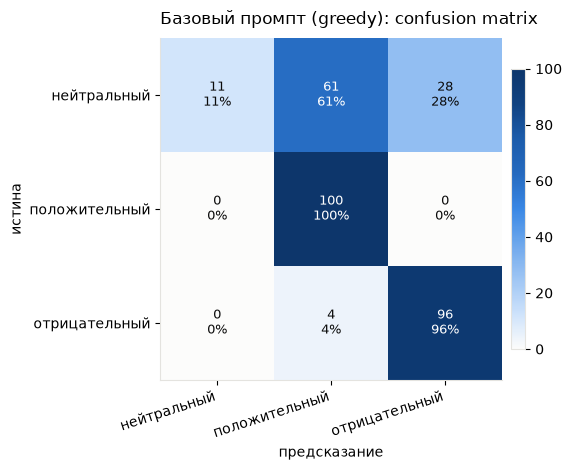

In [9]:
BASE_PROMPT = (
    "Определи тональность следующего текста. Ответь ровно одним словом: "
    "«положительный», «нейтральный» или «отрицательный». Не добавляй никаких пояснений.\n\n"
    "Текст: {text}\n"
    "Тональность:"
)

row_base, raws_base, preds_base = run_pipeline(
    "p1_base_ru", "2_base", BASE_PROMPT,
    gen=dict(strategy="greedy", do_sample=False, num_beams=1), max_new_tokens=8,
)
print("сырые ответы модели (первые 8):")
for t, r, y in list(zip(texts, raws_base, LABELS))[:8]:
    print(f"  [{CLASS_NAMES_RU[y]:13s}] {t[:48]!r:52s} -> {r!r}")
print(f"\n{row_base}")
print_report(preds_base, "Базовый промпт, greedy-декодинг")
plot_confusion(preds_base, "Базовый промпт (greedy): confusion matrix")

**Выводы по базовому промпту.** Формат выдержан идеально (parse rate 1.0 — явный список классов и префикс
«Тональность:» работают), accuracy 0.69, macro-F1 0.603. Главная проблема — **слепота к нейтральному классу**:
recall нейтральных всего 0.11 (F1 = 0.198) при precision 1.0. Модель стремится приписать полярность любому
тексту: вопрос «Как найти свободные места на яхте?» она уверенно считает положительным или отрицательным.
Иными словами, когда модель всё же говорит «нейтральный» — она почти всегда права, но говорит это редко.
Это наблюдение задаёт главную ось улучшений для п.3: заставить модель всерьёз рассматривать вариант «оценки нет».

## 3. Вариации prompt (п.3 задания)

Варьируем четыре оси: **строгость ограничений**, **формат вывода** (слово / буква / цифра / JSON / объяснение),
**язык** (RU/EN), **структура инструкции** (свободная / нумерованные правила / few-shot примеры).
Все варианты прогоняются в одинаковом режиме greedy на той же подвыборке.

| # | Промпт | Ось варьирования |
|---|---|---|
| p1 | базовый RU | контроль (из п.2) |
| p2 | свободный RU | без ограничений на ответ |
| p3 | нумерованные правила RU | более строгие ограничения |
| p4 | английский | язык инструкции |
| p5 | JSON | формат вывода |
| p6 | буква П/Н/О | формат вывода |
| p7 | цифра 0/1/2 | формат вывода |
| p8 | few-shot (3 примера) | структура инструкции |
| p9 | объяснение → метка | структура вывода (длинная генерация) |

In [10]:
PROMPTS = {
    "p1_base_ru": dict(
        tmpl=BASE_PROMPT, scheme="words", mnt=8, note="контроль: строгий, ответ одним словом"),
    "p2_loose_ru": dict(
        tmpl="Какая тональность у этого текста?\n\nТекст: {text}\nОтвет:",
        scheme="words", mnt=8, note="менее строгие ограничения"),
    "p3_rules_ru": dict(
        tmpl=("Выполни классификацию тональности текста по правилам:\n"
              "1. Прочитай текст.\n"
              "2. Определи, выражает ли он положительную, отрицательную или нейтральную оценку.\n"
              "3. Выведи ровно одну метку из списка: положительный | нейтральный | отрицательный.\n"
              "4. Запрещено выводить что-либо кроме метки: без объяснений, без знаков препинания, без кавычек.\n\n"
              "Текст: {text}\nМетка:"),
        scheme="words", mnt=8, note="более строгие ограничения (нумерованные правила)"),
    "p4_en": dict(
        tmpl=("Classify the sentiment of the following text. Answer with exactly one word: "
              "positive, neutral or negative. Do not explain.\n\nText: {text}\nSentiment:"),
        scheme="words", mnt=8, note="английский язык инструкции"),
    "p5_json_ru": dict(
        tmpl=("Определи тональность текста и верни ответ строго в формате JSON, без markdown и пояснений:\n"
              '{"sentiment": "положительный"} или {"sentiment": "нейтральный"} '
              'или {"sentiment": "отрицательный"}\n\nТекст: {text}\nJSON:'),
        scheme="words", mnt=14, note="формат вывода: JSON"),
    "p6_letter_ru": dict(
        tmpl=("Определи тональность текста. Ответь ровно одной буквой:\n"
              "П — положительный, Н — нейтральный, О — отрицательный.\n"
              "Выведи только одну букву: П, Н или О.\n\nТекст: {text}\nБуква:"),
        scheme="letters", mnt=4, note="формат вывода: одна буква П/Н/О"),
    "p7_digit_ru": dict(
        tmpl=("Задача классификации тональности. Классы закодированы цифрами:\n"
              "0 — нейтральный\n1 — положительный\n2 — отрицательный\n"
              "Выведи только цифру класса для следующего текста.\n\nТекст: {text}\nЦифра:"),
        scheme="digits", mnt=4, note="формат вывода: цифра класса 0/1/2"),
    "p8_fewshot_ru": dict(
        tmpl=("Определи тональность текста по примерам.\n\n"
              "Текст: Спасибо, вы очень помогли!\nТональность: положительный\n\n"
              "Текст: Собрание перенесли на четверг.\nТональность: нейтральный\n\n"
              "Текст: Опять забыли про мою заявку, крайне недоволен.\nТональность: отрицательный\n\n"
              "Текст: {text}\nТональность:"),
        scheme="words", mnt=8, note="структура инструкции: few-shot примеры"),
    "p9_explain_ru": dict(
        tmpl=("Ты анализируешь тональность текста. Сначала дай краткое объяснение в одном предложении, "
              "затем на новой строке выведи финальный ответ строго в виде:\n"
              "Тональность: <положительный|нейтральный|отрицательный>\n\nТекст: {text}"),
        scheme="words", mnt=48, note="структура вывода: объяснение, затем метка"),
}

rows3, raws3 = [], {}
for key, p in PROMPTS.items():
    row, raws_, _ = run_pipeline(
        key, "3_prompts", p["tmpl"], gen=dict(strategy="greedy", do_sample=False, num_beams=1),
        scheme=p["scheme"], max_new_tokens=p["mnt"], batch_size=16 if p["mnt"] > 16 else 32,
    )
    rows3.append({**row, "note": p["note"]})
    raws3[key] = raws_
    print(f"{key:14s} parse_rate={row['parse_rate']:.2f} acc={row['acc']:.3f} "
          f"f1_macro={row['f1_macro']:.3f} ({row['sec']} c)")

res3 = pd.DataFrame(rows3).sort_values("f1_macro", ascending=False).reset_index(drop=True)
res3[["name", "note", "parse_rate", "acc", "f1_macro", "f1_neu", "f1_pos", "f1_neg", "sec"]]

p1_base_ru     parse_rate=1.00 acc=0.690 f1_macro=0.603 (41.4 c)


p2_loose_ru    parse_rate=0.02 acc=0.353 f1_macro=0.207 (34.1 c)


p3_rules_ru    parse_rate=1.00 acc=0.833 f1_macro=0.824 (56.8 c)


p4_en          parse_rate=1.00 acc=0.720 f1_macro=0.675 (30.9 c)


p5_json_ru     parse_rate=1.00 acc=0.693 f1_macro=0.673 (48.4 c)


p6_letter_ru   parse_rate=1.00 acc=0.690 f1_macro=0.672 (39.2 c)


p7_digit_ru    parse_rate=1.00 acc=0.583 f1_macro=0.503 (40.4 c)


p8_fewshot_ru  parse_rate=0.41 acc=0.527 f1_macro=0.458 (54.0 c)


p9_explain_ru  parse_rate=1.00 acc=0.713 f1_macro=0.654 (94.0 c)


,name,note,parse_rate,acc,f1_macro,f1_neu,f1_pos,f1_neg,sec
0,p3_rules_ru,более строгие ограничения (нумерованные правила),1.0000,0.8333,0.8243,0.7073,0.8547,0.9109,56.8
1,p4_en,английский язык инструкции,1.0000,0.7200,0.6752,0.4000,0.7463,0.8792,30.9
2,p5_json_ru,формат вывода: JSON,1.0000,0.6933,0.6735,0.4564,0.7326,0.8315,48.4
3,p6_letter_ru,формат вывода: одна буква П/Н/О,1.0000,0.6900,0.6723,0.4912,0.8167,0.7090,39.2
4,p9_explain_ru,"структура вывода: объяснение, затем метка",1.0000,0.7133,0.6542,0.3333,0.7547,0.8744,94.0
5,p1_base_ru,"контроль: строгий, ответ одним словом",1.0000,0.6900,0.6034,0.1982,0.7547,0.8571,41.4
6,p7_digit_ru,формат вывода: цифра класса 0/1/2,1.0000,0.5833,0.5029,0.0769,0.6226,0.8090,40.4
7,p8_fewshot_ru,структура инструкции: few-shot примеры,0.4133,0.5267,0.4582,0.5000,0.7615,0.1132,54.0
8,p2_loose_ru,менее строгие ограничения,0.0200,0.3533,0.2069,0.5076,0.1132,0.0000,34.1


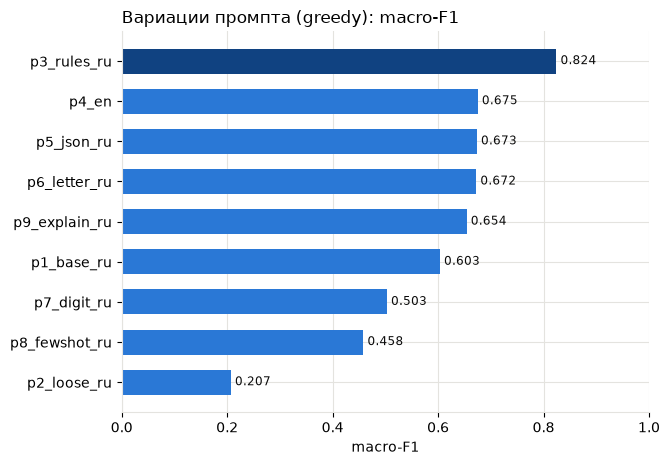

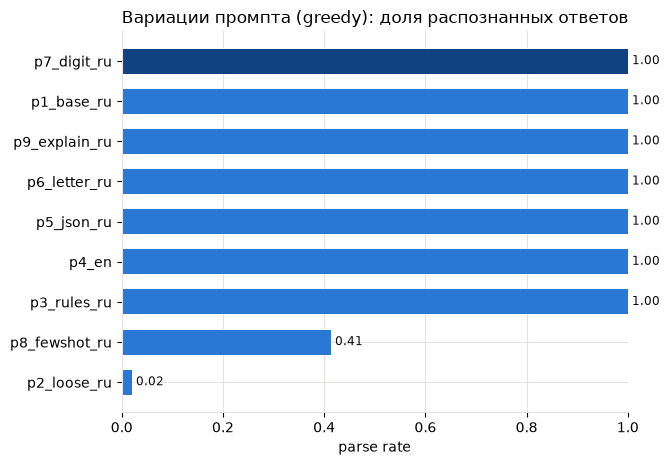

нераспознанные ответы [p2_loose_ru]:
  'Тональность этого текста может'
  'Этот текст имеет нейтр'
  'Текст имеет нейтраль'
  'Извините, но вы не'
  'Тональность этого текста может'

топ-3 промпта для п.4: ['p3_rules_ru', 'p4_en', 'p5_json_ru']


In [11]:
def hbars(d, col, title, xlabel, fmt="%.3f", xmax=1.0):
    d = d.sort_values(col)
    n = len(d)
    fig, ax = plt.subplots(figsize=(6.8, 0.4 * n + 1.15))
    colors = [C1] * n
    colors[-1] = C_DARK  # лучший результат — тёмный шаг того же оттенка
    bars = ax.barh(d["name"], d[col], color=colors, height=0.62)
    ax.bar_label(bars, fmt=fmt, color=INK, fontsize=8.5, padding=3)
    ax.set_xlim(0, xmax)
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left")
    fig.tight_layout()
    plt.show()


hbars(res3, "f1_macro", "Вариации промпта (greedy): macro-F1", "macro-F1")
hbars(res3, "parse_rate", "Вариации промпта (greedy): доля распознанных ответов", "parse rate", fmt="%.2f")

# примеры нераспознанных ответов у худшего по parse_rate варианта
worst = res3.sort_values("parse_rate").iloc[0]["name"]
sch = PROMPTS[worst]["scheme"]
bad = [r for r in raws3[worst] if parse_sentiment(r, sch) is None][:5]
print(f"нераспознанные ответы [{worst}]:")
for b in bad:
    print(f"  {b!r}")

TOP3 = res3.head(3)["name"].tolist()
print(f"\nтоп-3 промпта для п.4: {TOP3}")

**Выводы по вариациям промпта.** Разброс результатов огромный — macro-F1 от 0.207 до 0.824, формулировка
промпта оказалась самым мощным рычагом во всём ноутбуке:

* **Строгость ограничений — главный фактор.** Нумерованные правила (p3) дали +0.22 macro-F1 к базовому
  промпту (0.824 против 0.603) и заодно починили нейтральный класс: F1 нейтральных вырос с 0.198 до 0.707 —
  явный шаг «определи, выражает ли текст оценку» заставляет модель рассматривать «нет оценки» как
  полноправный исход. Свободная формулировка (p2) наоборот разваливает пайплайн: parse rate 2%, модель
  начинает развёрнутые фразы («Тональность этого текста может быть…»), которые не умещаются в лимит токенов
  и не парсятся, — без ограничения формата вывод непредсказуем.
* **Формат вывода.** Слова-метки — лучший формат. JSON (p5, 0.674) надёжен, но не добавляет качества и
  замедляет генерацию (лишние токены скобок и ключей). Буквы П/Н/О (p6, 0.672) чуть хуже слов. Цифры (p7,
  0.503) — худший формат: модель плохо держит в памяти соответствие «цифра → класс» (F1 нейтральных 0.077 —
  цифру 0 она почти не выдаёт).
* **Few-shot примеры (p8) неожиданно провалились**: parse rate 41%, macro-F1 0.458. Модель начинает
  «продолжать» шаблон примеров — генерирует следующий «Текст: …» вместо метки; распределение ответов
  сместилось (F1 отрицательных 0.113). Для инструктивной модели с жёстким chat-шаблоном явные правила
  в user-сообщении работают лучше, чем inline-примеры.
* **Язык.** Английская инструкция (p4, 0.675) чуть лучше базовой русской (0.603) — сказывается обилие
  англоязычных sentiment-данных при обучении, но строгая русская инструкция (p3) легко обгоняет обе.
* **«Объяснение → метка» (p9)** не помогло (0.654 против 0.824) и оказалось в 2.3 раза дороже по времени
  (94 с против 41 с): для простой классификации коротких текстов цепочка рассуждений добавляет шум,
  а не обоснование.

## 4. Добавление system prompt (п.4 задания)

Три system-промпта разной «роли»: RU-эксперт (мягкая роль), RU-«машина-классификатор» (жёсткая роль,
запрещает всё кроме метки), EN-классификатор (роль + английский). Кросс с топ-3 промптами из п.3
(+ строки «без system» из п.3 как контроль, у них дефолтный Qwen-промпт шаблона).

In [12]:
SYSTEMS = {
    "sys1_ru_expert": "Ты — эксперт по анализу тональности русскоязычных текстов. Отвечай кратко и по делу.",
    "sys2_ru_machine": ("Ты — автоматическая система классификации тональности. Ты не общаешься с пользователем "
                        "и выводишь только метку класса: положительный, нейтральный или отрицательный. "
                        "Любой другой ответ считается ошибкой."),
    "sys3_en": ("You are a sentiment classification system. For every request you reply with exactly one label: "
                "positive, neutral or negative. Any other output is an error."),
}

rows4 = []
for key in TOP3:
    p = PROMPTS[key]
    for sys_name, sys_text in SYSTEMS.items():
        row, _, _ = run_pipeline(
            f"{key}+{sys_name}", "4_system", p["tmpl"], system=sys_text,
            gen=dict(strategy="greedy", do_sample=False, num_beams=1),
            scheme=p["scheme"], max_new_tokens=p["mnt"], batch_size=32,
        )
        rows4.append(row)
        print(f"{key:14s} + {sys_name:15s} acc={row['acc']:.3f} f1_macro={row['f1_macro']:.3f} "
              f"parse={row['parse_rate']:.2f} ({row['sec']} c)")

res4 = pd.DataFrame(rows4)
res4[["name", "parse_rate", "acc", "f1_macro", "f1_neu", "f1_pos", "f1_neg"]]

p3_rules_ru    + sys1_ru_expert  acc=0.817 f1_macro=0.801 parse=1.00 (60.9 c)


p3_rules_ru    + sys2_ru_machine acc=0.810 f1_macro=0.793 parse=1.00 (66.7 c)


p3_rules_ru    + sys3_en         acc=0.787 f1_macro=0.761 parse=1.00 (59.9 c)


p4_en          + sys1_ru_expert  acc=0.770 f1_macro=0.743 parse=1.00 (34.6 c)


p4_en          + sys2_ru_machine acc=0.793 f1_macro=0.775 parse=1.00 (40.5 c)


p4_en          + sys3_en         acc=0.723 f1_macro=0.668 parse=1.00 (34.0 c)


p5_json_ru     + sys1_ru_expert  acc=0.757 f1_macro=0.747 parse=1.00 (52.1 c)


p5_json_ru     + sys2_ru_machine acc=0.793 f1_macro=0.782 parse=1.00 (58.1 c)


p5_json_ru     + sys3_en         acc=0.723 f1_macro=0.714 parse=1.00 (51.1 c)


,name,parse_rate,acc,f1_macro,f1_neu,f1_pos,f1_neg
0,p3_rules_ru+sys1_ru_expert,1.0,0.8167,0.8015,0.6579,0.9245,0.8220
1,p3_rules_ru+sys2_ru_machine,1.0,0.8100,0.7932,0.6447,0.8439,0.8910
2,p3_rules_ru+sys3_en,1.0,0.7867,0.7608,0.5734,0.8333,0.8756
3,p4_en+sys1_ru_expert,1.0,0.7700,0.7425,0.5352,0.8065,0.8857
4,p4_en+sys2_ru_machine,1.0,0.7933,0.7753,0.6174,0.8197,0.8889
5,p4_en+sys3_en,1.0,0.7233,0.6679,0.3651,0.8032,0.8356
6,p5_json_ru+sys1_ru_expert,1.0,0.7567,0.7470,0.5917,0.8032,0.8462
7,p5_json_ru+sys2_ru_machine,1.0,0.7933,0.7819,0.6415,0.8163,0.8878
8,p5_json_ru+sys3_en,1.0,0.7233,0.7144,0.6300,0.8163,0.6968


macro-F1: промпт x system prompt
system       без system (дефолт Qwen)  sys1_ru_expert  sys2_ru_machine  sys3_en
prompt                                                                         
p3_rules_ru                     0.824           0.802            0.793    0.761
p4_en                           0.675           0.742            0.775    0.668
p5_json_ru                      0.674           0.747            0.782    0.714


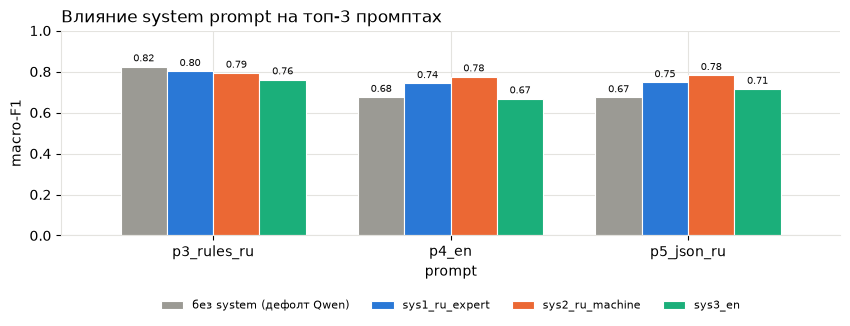

лучшая пара для п.5: промпт = p3_rules_ru (более строгие ограничения (нумерованные правила)), system = None -> f1_macro=0.8243, acc=0.8333


In [13]:
# сводная таблица: промпт x system prompt (f1_macro), контроль «без system» взят из п.3
rows3_short = res3[res3["name"].isin(TOP3)].copy()
rows3_short["system"] = "без system (дефолт Qwen)"
rows4_short = res4.copy()
rows4_short["prompt"] = rows4_short["name"].str.split("+").str[0]
rows4_short["system"] = rows4_short["name"].str.split("+").str[1]
rows3_short["prompt"] = rows3_short["name"]

all4 = pd.concat([rows3_short, rows4_short], ignore_index=True)
all4["prompt"] = pd.Categorical(all4["prompt"], categories=TOP3, ordered=True)
piv = all4.pivot_table(index="prompt", columns="system", values="f1_macro", observed=False)
piv = piv[["без system (дефолт Qwen)", "sys1_ru_expert", "sys2_ru_machine", "sys3_en"]]
print("macro-F1: промпт x system prompt")
print(piv.round(3).to_string())

fig, ax = plt.subplots(figsize=(8.6, 3.7))
piv.plot(kind="bar", ax=ax, color=["#9b9a94", C1, C2, C3], width=0.78, edgecolor="white", linewidth=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=7.5, color=INK, padding=2)
ax.set_ylabel("macro-F1")
ax.set_title("Влияние system prompt на топ-3 промптах", loc="left")
ax.set_ylim(0, 1.0)
ax.legend(title="", ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.42), frameon=False, fontsize=8)
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

# фиксируем лучшую пару (system prompt + prompt) по f1_macro, при равенстве — accuracy и parse_rate
cand = all4.sort_values(["f1_macro", "acc", "parse_rate"])
best = cand.iloc[-1]
BEST_PROMPT_KEY = best["prompt"]
BEST_SYSTEM_KEY = best["system"] if str(best["system"]).startswith("sys") else None
BEST_SYSTEM = SYSTEMS.get(BEST_SYSTEM_KEY)
print(f"лучшая пара для п.5: промпт = {BEST_PROMPT_KEY} ({PROMPTS[BEST_PROMPT_KEY]['note']}), "
      f"system = {BEST_SYSTEM_KEY} -> f1_macro={best['f1_macro']}, acc={best['acc']}")

**Выводы по system prompt.** Картина асимметричная — system prompt **вытягивает слабые промпты,
но не улучшает сильный**:

* Для лучших пар в топ-3 добавление любого system prompt не помогло: p3 остался на 0.824 *без* system
  (т.е. с дефолтным «You are Qwen…» из шаблона), с системами он просел до 0.793–0.802. Когда задача уже
  полностью специфицирована в user-сообщении, дополнительная роль только слегка сдвигает поведение модели.
* А вот для слабых промптов жёсткая роль «машины-классификатора» (sys2) стала вторым по силе приёмом
  после правил: p4_en 0.675 → 0.775 (+0.10), p5_json 0.674 → 0.782 (+0.11). Мягкая роль эксперта (sys1)
  тоже помогала (+0.07). System prompt компенсирует недоописанность инструкции, но не заменяет её.
* Английский system (sys3) в паре с русскими промптами работал хуже всего (p3: 0.761) — смешение языков
  роли и задачи слегка путает модель 1.5B.

**Лучшая пара для п.5: `p3_rules_ru` без явного system prompt** (macro-F1 0.824, accuracy 0.833).

## 5. Стратегии и параметры генерации (п.5 задания)

Лучшая пара из п.4 фиксируется; варьируем только декодинг:

* **greedy** — контроль из п.4;
* **beam search** (3 и 5 лучей) — максимизация правдоподобия последовательности;
* **чистое сэмплирование** с температурой 0.5 / 0.7 / 1.0 (top-k и top-p выключены);
* **top-k** (20, 50) и **top-p** (0.8, 0.95) при температуре 0.7;
* **self-consistency** — 5 сэмплов (t=0.7, top-p=0.95) и голосование большинством;
  при равенстве голосов детерминированный тай-брейк — меньшая метка.

`repetition_penalty=1.0` у всех конфигураций (дефолт Qwen 1.1 отключён для сопоставимости).
Сэмплирование стохастично; для воспроизводимости перед каждым конфигом фиксируется seed.

In [14]:
BP = PROMPTS[BEST_PROMPT_KEY]
GEN_CONFIGS = {
    "greedy": dict(strategy="greedy"),
    "beam3": dict(strategy="beam", num_beams=3),
    "beam5": dict(strategy="beam", num_beams=5),
    "sample_t0.5": dict(strategy="sample", do_sample=True, temperature=0.5, top_k=0, top_p=1.0),
    "sample_t0.7": dict(strategy="sample", do_sample=True, temperature=0.7, top_k=0, top_p=1.0),
    "sample_t1.0": dict(strategy="sample", do_sample=True, temperature=1.0, top_k=0, top_p=1.0),
    "topk20_t0.7": dict(strategy="sample", do_sample=True, temperature=0.7, top_k=20, top_p=1.0),
    "topk50_t0.7": dict(strategy="sample", do_sample=True, temperature=0.7, top_k=50, top_p=1.0),
    "topp0.8_t0.7": dict(strategy="sample", do_sample=True, temperature=0.7, top_k=0, top_p=0.8),
    "topp0.95_t0.7": dict(strategy="sample", do_sample=True, temperature=0.7, top_k=0, top_p=0.95),
}

rows5, preds5 = [], {}
for name, g in GEN_CONFIGS.items():
    row, _, preds_ = run_pipeline(
        name, "5_gen", BP["tmpl"], system=BEST_SYSTEM, gen=g,
        scheme=BP["scheme"], max_new_tokens=BP["mnt"], batch_size=32,
    )
    rows5.append(row)
    preds5[name] = preds_
    print(f"{name:14s} acc={row['acc']:.3f} f1_macro={row['f1_macro']:.3f} parse={row['parse_rate']:.2f} ({row['sec']} c)")

# self-consistency: 5 сэмплов на текст + голосование большинством
SC_GEN = dict(strategy="sample+vote", do_sample=True, temperature=0.7, top_k=0, top_p=0.95, n=5)
t0 = time.time()
variants = generate(texts, BP["tmpl"], system=BEST_SYSTEM, gen=SC_GEN,
                    max_new_tokens=BP["mnt"], batch_size=16, n=5)
sc_sec = round(time.time() - t0, 1)
votes, n_parsed_votes = [], []
for vs in variants:
    pv = [v for v in (parse_sentiment(x, BP["scheme"]) for x in vs) if v is not None]
    n_parsed_votes.append(len(pv))
    if not pv:
        votes.append(0)  # ни один вариант не распознан -> нейтральный
        continue
    c = Counter(pv)
    top_cnt = max(c.values())
    votes.append(min(l for l, k in c.items() if k == top_cnt))  # тай-брейк: меньшая метка
preds5["self_cons_n5"] = votes
rows5.append(score_preds("self_cons_n5", "5_gen", votes, SC_GEN, extra={
    "parse_rate": round(float(np.mean([v > 0 for v in n_parsed_votes])), 4),  # доля текстов с >=1 распознанным сэмплом
    "sec": sc_sec, "n": len(texts),
}))
print(f"self_cons_n5  acc={rows5[-1]['acc']:.3f} f1_macro={rows5[-1]['f1_macro']:.3f} ({sc_sec} c)")

res5 = pd.DataFrame(rows5).sort_values("f1_macro", ascending=False).reset_index(drop=True)
res5[["name", "parse_rate", "acc", "f1_macro", "f1_neu", "f1_pos", "f1_neg", "sec"]]

greedy         acc=0.833 f1_macro=0.824 parse=1.00 (56.7 c)


beam3          acc=0.840 f1_macro=0.831 parse=1.00 (171.1 c)


beam5          acc=0.840 f1_macro=0.831 parse=1.00 (289.7 c)


sample_t0.5    acc=0.833 f1_macro=0.824 parse=1.00 (56.7 c)


sample_t0.7    acc=0.820 f1_macro=0.810 parse=0.98 (57.0 c)


...

topk50_t0.7    acc=0.820 f1_macro=0.810 parse=0.98 (57.3 c)


topp0.8_t0.7   acc=0.830 f1_macro=0.821 parse=1.00 (56.9 c)


topp0.95_t0.7  acc=0.823 f1_macro=0.812 parse=1.00 (57.0 c)


self_cons_n5  acc=0.833 f1_macro=0.826 (261.8 c)


,name,parse_rate,acc,f1_macro,f1_neu,f1_pos,f1_neg,sec
0,beam3,1.0000,0.8400,0.8308,0.7160,0.8547,0.9216,171.1
1,beam5,1.0000,0.8400,0.8308,0.7160,0.8547,0.9216,289.7
2,self_cons_n5,1.0000,0.8333,0.8255,0.7108,0.8511,0.9146,261.8
3,greedy,1.0000,0.8333,0.8243,0.7073,0.8547,0.9109,56.7
4,sample_t0.5,0.9967,0.8333,0.8237,0.7037,0.8511,0.9163,56.7
5,topp0.8_t0.7,1.0000,0.8300,0.8207,0.7037,0.8475,0.9109,56.9
6,topp0.95_t0.7,1.0000,0.8233,0.8123,0.6875,0.8475,0.9020,57.0
7,sample_t0.7,0.9800,0.8200,0.8101,0.6829,0.8348,0.9126,57.0
8,topk20_t0.7,0.9800,0.8200,0.8101,0.6829,0.8348,0.9126,57.3
9,topk50_t0.7,0.9800,0.8200,0.8101,0.6829,0.8348,0.9126,57.3


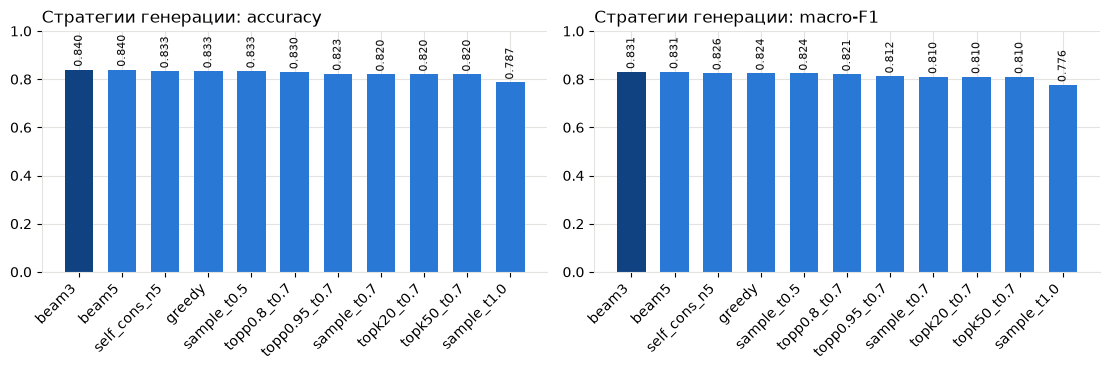

доля предсказаний, совпадающих с greedy:
       config  agreement_with_greedy
       greedy                  1.000
        beam3                  0.993
        beam5                  0.993
 self_cons_n5                  0.987
 topp0.8_t0.7                  0.973
  sample_t0.5                  0.967
topp0.95_t0.7                  0.953
  sample_t0.7                  0.950
  topk20_t0.7                  0.950
  topk50_t0.7                  0.950
  sample_t1.0                  0.913

примеры, где self-consistency расходится с greedy:
  [нейтральный  ] 'Это устройство требует подключения к источнику энерг'
    сэмплы: [0, 2, 2, 0, 0], голос=0, greedy=2
  [нейтральный  ] 'Я хочу поучаствовать'
    сэмплы: [1, 1, 1, 1, 0], голос=1, greedy=0
  [нейтральный  ] 'Почему мед все еще приходит в маленьких упаковках? Н'
    сэмплы: [0, 0, 2, 0, 2], голос=0, greedy=2
  [отрицательный] 'Судя по новой голосовалке, мультитул растворился в т'
    сэмплы: [0, 2, 0, 2, 0], голос=0, greedy=2


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.8))
for ax, col, title in zip(axes, ["acc", "f1_macro"],
                          ["Стратегии генерации: accuracy", "Стратегии генерации: macro-F1"]):
    d = res5.sort_values(col, ascending=False)
    colors = [C1] * len(d)
    colors[0] = C_DARK
    bars = ax.bar(d["name"], d[col], color=colors, width=0.66)
    ax.bar_label(bars, fmt="%.3f", fontsize=8, color=INK, padding=2, rotation=90)
    ax.set_ylim(0, 1.0)
    ax.set_title(title, loc="left")
    ax.tick_params(axis="x", rotation=45)
    for lbl in ax.get_xticklabels():
        lbl.set_ha("right")
fig.tight_layout()
plt.show()

# согласованность конфигураций с greedy (доля одинаковых предсказаний)
greedy_preds = np.array(preds5["greedy"])
agree = pd.DataFrame([
    {"config": name, "agreement_with_greedy": round(float(np.mean(np.array(p) == greedy_preds)), 3)}
    for name, p in preds5.items()
]).sort_values("agreement_with_greedy", ascending=False)
print("доля предсказаний, совпадающих с greedy:")
print(agree.to_string(index=False))

# примеры расхождений self-consistency с greedy (модель «колеблется» на этих текстах)
sc_arr, gr_arr = np.array(preds5["self_cons_n5"]), greedy_preds
diff_idx = np.where(sc_arr != gr_arr)[0][:5]
print("\nпримеры, где self-consistency расходится с greedy:")
for i in diff_idx:
    print(f"  [{CLASS_NAMES_RU[LABELS[i]]:13s}] {texts[i][:52]!r}")
    print(f"    сэмплы: {[parse_sentiment(v, BP['scheme']) for v in variants[i]]}, "
          f"голос={sc_arr[i]}, greedy={gr_arr[i]}")

**Выводы по стратегиям и параметрам генерации.** На хорошо сконструированном промпте (parse rate ~1.0)
выбор стратегии декодинга влияет на порядок меньше, чем формулировка промпта: весь разброс — от 0.776 до 0.831
против 0.22 у промптов:

* **Beam search** — единственная стратегия, обошедшая greedy: beam3 0.831 против 0.824 (+0.007) при
  совпадении 99.3% предсказаний. beam5 дал ровно тот же результат, что beam3, но за 5× времени — для ответа
  в одно слово дополнительная глубина луча уже ничего не меняет.
* **Сэмплирование деградирует монотонно с ростом температуры**: t=0.5 повторяет greedy (0.824),
  t=0.7 — 0.810, t=1.0 — 0.776; вместе с качеством падает и parse rate (1.00 → 0.97). top-k/top-p
  при t=0.7 практически не отличимы от чистой температуры (0.810–0.821) — доминирует именно температура;
  из фильтров чуть лучше всех top_p=0.8.
* **Self-consistency (5 сэмплов + голосование)** дала 0.826 — на уровне greedy при 4.6× времени.
  Ценность метода видна в примерах расхождений: неустойчивые тексты — почти все нейтральные или спорные,
  сэмплы разделяются like [0, 2, 2, 0, 0] — это готовый **детектор неопределённости**, но не способ
  поднять accuracy на детерминированной задаче с доминирующим классом-ответом.
* Согласованность с greedy: beam 0.993, self-consistency 0.987, t=1.0 — 0.913.

**Практический вывод:** для классификации с жёстким форматом ответа оптимален greedy (лучшая цена/качество);
beam3 — если важен каждый пункт метрики; высокие температуры вредны и качеству, и парсингу.

## 6. Итоговые результаты

Сводка по всем экспериментам ноутбука (лог `logs/metrics.jsonl`): топ-10 конфигураций и лучшие
конфигурации каждого раздела.

In [16]:
all_df = pd.DataFrame([json.loads(l) for l in LOG.read_text(encoding="utf-8").splitlines() if l.strip()])
top10 = all_df.sort_values(["f1_macro", "acc"], ascending=False).head(10)
print("топ-10 конфигураций по macro-F1:")
print(top10[["section", "name", "acc", "f1_macro", "parse_rate"]].to_string(index=False))

print("\nлучшая конфигурация каждого раздела:")
best_each = all_df.loc[all_df.groupby("section")["f1_macro"].idxmax()]
print(best_each[["section", "name", "acc", "f1_macro", "parse_rate"]].to_string(index=False))

топ-10 конфигураций по macro-F1:
  section          name    acc  f1_macro  parse_rate
    5_gen         beam3 0.8400    0.8308      1.0000
    5_gen         beam5 0.8400    0.8308      1.0000
    5_gen  self_cons_n5 0.8333    0.8255      1.0000
3_prompts   p3_rules_ru 0.8333    0.8243      1.0000
    5_gen        greedy 0.8333    0.8243      1.0000
    5_gen   sample_t0.5 0.8333    0.8237      0.9967
    5_gen  topp0.8_t0.7 0.8300    0.8207      1.0000
    5_gen topp0.95_t0.7 0.8233    0.8123      1.0000
    5_gen   sample_t0.7 0.8200    0.8101      0.9800
    5_gen   topk20_t0.7 0.8200    0.8101      0.9800

лучшая конфигурация каждого раздела:
  section                       name    acc  f1_macro  parse_rate
   2_base                 p1_base_ru 0.6900    0.6034         1.0
3_prompts                p3_rules_ru 0.8333    0.8243         1.0
 4_system p3_rules_ru+sys1_ru_expert 0.8167    0.8015         1.0
    5_gen                      beam3 0.8400    0.8308         1.0


**Финальные выводы.**

1. **Иерархия рычагов качества** (по величине эффекта на macro-F1):
   формулировка промпта (**+0.22**: 0.603 → 0.824) ≫ system prompt для слабых промптов (**до +0.11**,
   сильные не улучшает) ≫ стратегия генерации (**≤ +0.007**). Порядок работы правильный: сначала промпт,
   потом система роли, и только в конце — тонкая настройка декодинга.
2. **Что сработало в промпте:** явная пошаговая процедура с отдельным шагом «есть ли оценка вообще»
   (починила нейтральный класс: F1 0.198 → 0.707), закрытый список меток, прямой префикс ответа,
   запрет всего лишнего. **Что провалилось:** свободная формулировка (parse 2%), few-shot примеры
   (модель продолжает шаблон примеров), кодирование классов цифрами (модель путает маппинг),
   «объясни потом ответь» (дороже и хуже).
3. **System prompt** полезен как компенсатор недоописанной инструкции (жёсткая роль «классификатора»),
   но лучшая пара — строгий промпт с дефолтным Qwen-промптом шаблона.
4. **Декодинг:** beam3/beam5 — максимум (0.831), greedy практически тот же (0.824) при в разы меньшей цене;
   сэмплирование с высокой температурой вредит; self-consistency — детектор неопределённости
   (спорные тексты дают расколотые голоса), а не бустер метрики.
5. **Остаточные ошибки** сосредоточены в нейтральном классе (максимальный F1 нейтральных 0.72 против
   0.85–0.92 у полярных) — это и ирония/сарказм в коротких неформальных текстах, и шум разметки:
   потолок задачи ниже 100% и в принципе доучивается только моделью большего размера.